# BRACOL: classificação de estresses bióticos em folhas de café

Mesmo problema e mesmo dataset, duas soluções:

1. **ML clássico**: pré-processamento, atributos de cor, LBP, Haralick (GLCM) e HOG, classificadores SVM, Random Forest, KNN e Regressão Logística.
2. **Deep Learning**: Ultralytics YOLO em modo classificação, com transferência de aprendizado (pesos ImageNet).

Dataset: subconjunto *symptom* do BRACOL (Esgario, Krohling e Ventura, 2019), 5 classes, divisão oficial treino/validação/teste.
Protocolo: o treino ajusta os modelos, a validação escolhe hiperparâmetros e checkpoint, o teste é usado uma única vez no fim.

In [1]:
import json, time, random
from pathlib import Path

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tqdm.auto import tqdm
from skimage.feature import local_binary_pattern, graycomatrix, graycoprops, hog
from sklearn.base import clone
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import ParameterGrid
from sklearn.metrics import (f1_score, precision_score, recall_score, accuracy_score,
                             classification_report, confusion_matrix, ConfusionMatrixDisplay)
import joblib

SEED = 42
random.seed(SEED); np.random.seed(SEED)

ROOT = Path.cwd()
DATA = ROOT / 'data/coffee-datasets/symptom'
OUT = ROOT / 'results'; OUT.mkdir(exist_ok=True)

# YOLO27 não está publicado no ultralytics 8.4.210 (yolo27s-cls.pt não baixa); troque aqui quando sair.
YOLO_MODEL = 'yolo26s-cls.pt'
IMGSZ = 224
EPOCHS = 60

CLASSES = sorted(p.name for p in (DATA / 'train').iterdir())
NOMES = {'1_health': 'saudável', '2_miner': 'bicho-mineiro', '3_rust': 'ferrugem',
         '4_phoma': 'phoma', '5_cercospora': 'cercospora'}
LABELS = [NOMES[c] for c in CLASSES]
CLASSES

/home/noirelab/visao-bracol/.venv/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


['1_health', '2_miner', '3_rust', '4_phoma', '5_cercospora']

## 1. Dataset

In [2]:
def listar(split):
    paths, ys = [], []
    for i, c in enumerate(CLASSES):
        fs = sorted((DATA / split / c).glob('*.jpg'))
        paths += fs; ys += [i] * len(fs)
    return paths, np.array(ys)

splits = {s: listar(s) for s in ['train', 'val', 'test']}
contagem = pd.DataFrame({s: np.bincount(y, minlength=len(CLASSES)) for s, (_, y) in splits.items()}, index=LABELS)
contagem.loc['total'] = contagem.sum()
contagem

,train,val,test
saudável,182,40,39
bicho-mineiro,374,83,83
ferrugem,434,93,94
phoma,325,70,69
cercospora,224,49,50
total,1539,335,335


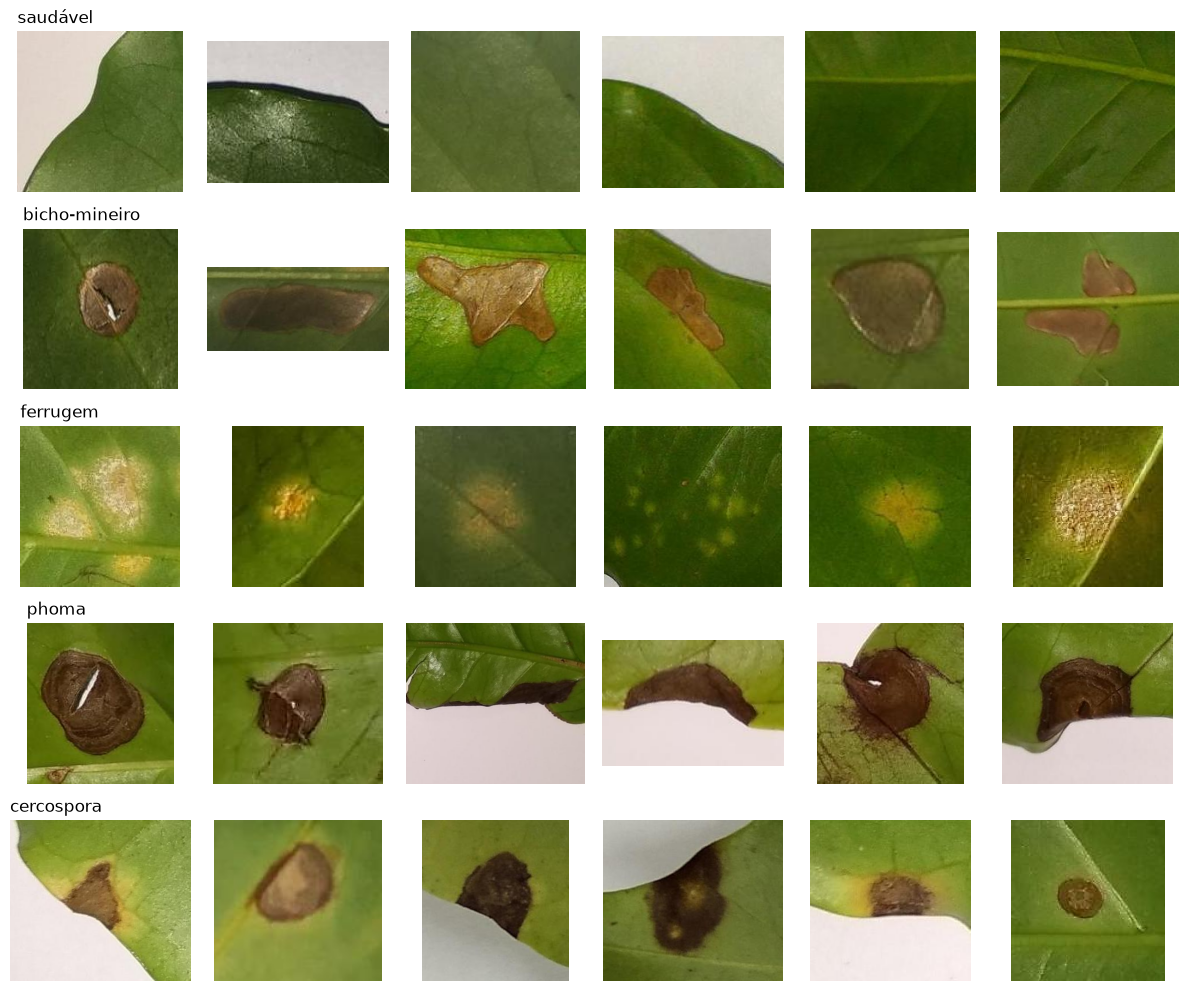

In [3]:
fig, axs = plt.subplots(len(CLASSES), 6, figsize=(12, 10))
for i, c in enumerate(CLASSES):
    fs = sorted((DATA / 'train' / c).glob('*.jpg'))
    for j, f in enumerate(random.sample(fs, 6)):
        axs[i, j].imshow(cv2.cvtColor(cv2.imread(str(f)), cv2.COLOR_BGR2RGB)); axs[i, j].axis('off')
    axs[i, 0].set_title(LABELS[i], loc='left')
plt.tight_layout(); plt.savefig(OUT / 'amostras.png', dpi=120); plt.show()

## 2. Solução ML clássica

**Pré-processamento**: redimensiona para 128×128 (INTER_AREA), converte para HSV, Lab e tons de cinza.

**Atributos** (por grupo, para permitir ablação):
- `cor`: histogramas H (18 bins), S e V (8 bins cada), média e desvio padrão em Lab. Ferrugem é amarela-alaranjada, phoma e cercospora são marrons, a folha sadia é verde.
- `lbp`: histogramas LBP uniformes (P=8, R=1 e P=16, R=2), textura invariante a rotação.
- `glcm`: atributos de Haralick (contraste, dissimilaridade, homogeneidade, energia, correlação, ASM) em distâncias 1 e 3, média de 4 ângulos.
- `hog`: HOG 9 orientações em 64×64. Depende da orientação da lesão, entra como hipótese a testar.

In [4]:
TAM = 128

def atributos(path):
    img = cv2.resize(cv2.imread(str(path)), (TAM, TAM), interpolation=cv2.INTER_AREA)
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)
    lab = cv2.cvtColor(img, cv2.COLOR_BGR2LAB).reshape(-1, 3).astype(np.float32)

    hist = [cv2.calcHist([hsv], [k], None, [b], [0, r]).ravel() for k, b, r in [(0, 18, 180), (1, 8, 256), (2, 8, 256)]]
    cor = np.concatenate([h / h.sum() for h in hist] + [lab.mean(0) / 255, lab.std(0) / 255])

    lbp = np.concatenate([np.histogram(local_binary_pattern(gray, P, R, 'uniform'), bins=P + 2, range=(0, P + 2), density=True)[0]
                          for P, R in [(8, 1), (16, 2)]])

    g = graycomatrix(gray // 8, [1, 3], [0, np.pi / 4, np.pi / 2, 3 * np.pi / 4], levels=32, symmetric=True, normed=True)
    glcm = np.concatenate([graycoprops(g, p).mean(1) for p in ['contrast', 'dissimilarity', 'homogeneity', 'energy', 'correlation', 'ASM']])

    h = hog(cv2.resize(gray, (64, 64)), orientations=9, pixels_per_cell=(16, 16), cells_per_block=(2, 2))
    return {'cor': cor, 'lbp': lbp, 'glcm': glcm, 'hog': h}

feats = {s: [atributos(p) for p in tqdm(paths, desc=f'atributos {s}')] for s, (paths, _) in splits.items()}
y = {s: ys for s, (_, ys) in splits.items()}
{k: v.shape[0] for k, v in feats['train'][0].items()}

atributos train:   0%|          | 0/1539 [00:00<?, ?it/s]

atributos train:   1%|          | 9/1539 [00:00<00:17, 85.40it/s]

atributos train:   2%|▏         | 26/1539 [00:00<00:11, 131.87it/s]

atributos train:   3%|▎         | 42/1539 [00:00<00:10, 144.42it/s]

atributos train:   4%|▍         | 59/1539 [00:00<00:09, 151.25it/s]

atributos train:   5%|▍         | 76/1539 [00:00<00:09, 155.46it/s]

... (126 outputs left out)

atributos test:  91%|█████████▏| 306/335 [00:01<00:00, 163.96it/s]

atributos test:  96%|█████████▋| 323/335 [00:01<00:00, 163.29it/s]

atributos test: 100%|██████████| 335/335 [00:02<00:00, 163.75it/s]

{'cor': 40, 'lbp': 28, 'glcm': 12, 'hog': 324}

In [5]:
def matriz(split, grupos):
    return np.stack([np.concatenate([f[g] for g in grupos]) for f in feats[split]])

def f1_macro(yt, yp):
    return f1_score(yt, yp, average='macro')

### 2.1 Ablação de atributos (SVM RBF fixo, F1 macro na validação)

In [6]:
CONJUNTOS = {
    'cor': ['cor'], 'lbp': ['lbp'], 'glcm': ['glcm'], 'hog': ['hog'],
    'cor+lbp+glcm': ['cor', 'lbp', 'glcm'],
    'cor+lbp+glcm+hog': ['cor', 'lbp', 'glcm', 'hog'],
}
svm_base = make_pipeline(StandardScaler(), SVC(C=10, gamma='scale', class_weight='balanced'))
ablacao = {}
for nome, grupos in tqdm(CONJUNTOS.items(), desc='ablação'):
    m = clone(svm_base).fit(matriz('train', grupos), y['train'])
    ablacao[nome] = f1_macro(y['val'], m.predict(matriz('val', grupos)))
ablacao = pd.Series(ablacao, name='F1 macro (val)').sort_values(ascending=False)
ablacao.to_frame()

ablação:   0%|          | 0/6 [00:00<?, ?it/s]

ablação:  50%|█████     | 3/6 [00:00<00:00, 20.16it/s]

ablação: 100%|██████████| 6/6 [00:00<00:00,  9.64it/s]

ablação: 100%|██████████| 6/6 [00:00<00:00, 10.45it/s]

,F1 macro (val)
cor+lbp+glcm,0.845006
cor+lbp+glcm+hog,0.811065
cor,0.774485
lbp,0.686232
hog,0.624593
glcm,0.570521


In [7]:
GRUPOS = CONJUNTOS[ablacao.index[0]]
Xtr, Xva, Xte = (matriz(s, GRUPOS) for s in ['train', 'val', 'test'])
print('conjunto escolhido:', ablacao.index[0], '| dimensão:', Xtr.shape[1])

conjunto escolhido: cor+lbp+glcm | dimensão: 80


### 2.2 Seleção de classificador e hiperparâmetros

Cada combinação treina só no treino e é avaliada na validação. O teste não entra aqui.

In [8]:
MODELOS = {
    'SVM (RBF)': (SVC(class_weight='balanced', random_state=SEED), {'C': [1, 10, 100], 'gamma': ['scale', 0.01, 0.001]}),
    'Random Forest': (RandomForestClassifier(n_estimators=400, class_weight='balanced', n_jobs=-1, random_state=SEED),
                      {'max_depth': [None, 20], 'max_features': ['sqrt', 0.3]}),
    'KNN': (KNeighborsClassifier(), {'n_neighbors': [3, 5, 9, 15], 'weights': ['uniform', 'distance']}),
    'Regressão Logística': (LogisticRegression(max_iter=5000, class_weight='balanced'), {'C': [0.1, 1, 10]}),
}
busca = []
for nome, (est, grade) in MODELOS.items():
    for params in tqdm(list(ParameterGrid(grade)), desc=nome):
        m = make_pipeline(StandardScaler(), clone(est).set_params(**params)).fit(Xtr, y['train'])
        busca.append({'modelo': nome, 'params': params, 'f1_val': f1_macro(y['val'], m.predict(Xva))})
busca = pd.DataFrame(busca)
melhores = busca.loc[busca.groupby('modelo')['f1_val'].idxmax()].sort_values('f1_val', ascending=False)
melhores

SVM (RBF):   0%|          | 0/9 [00:00<?, ?it/s]

SVM (RBF):  33%|███▎      | 3/9 [00:00<00:00, 21.76it/s]

SVM (RBF):  67%|██████▋   | 6/9 [00:00<00:00, 23.50it/s]

SVM (RBF): 100%|██████████| 9/9 [00:00<00:00, 23.83it/s]

SVM (RBF): 100%|██████████| 9/9 [00:00<00:00, 23.53it/s]

Random Forest:   0%|          | 0/4 [00:00<?, ?it/s]

... (7 outputs left out)

Regressão Logística:   0%|          | 0/3 [00:00<?, ?it/s]

Regressão Logística: 100%|██████████| 3/3 [00:00<00:00, 19.12it/s]

Regressão Logística: 100%|██████████| 3/3 [00:00<00:00, 19.06it/s]

,modelo,params,f1_val
8,SVM (RBF),"{'C': 100, 'gamma': 0.001}",0.866500
22,Regressão Logística,{'C': 1},0.858202
10,Random Forest,"{'max_depth': None, 'max_features': 0.3}",0.852318
14,KNN,"{'n_neighbors': 3, 'weights': 'distance'}",0.727398


In [9]:
nome_ml, params_ml = melhores.iloc[0]['modelo'], melhores.iloc[0]['params']
ml = make_pipeline(StandardScaler(), clone(MODELOS[nome_ml][0]).set_params(**params_ml)).fit(Xtr, y['train'])
joblib.dump({'modelo': ml, 'grupos': GRUPOS, 'classes': CLASSES}, OUT / 'ml_classico.joblib')

t0 = time.perf_counter()
pred_ml = ml.predict(np.stack([np.concatenate([atributos(p)[g] for g in GRUPOS]) for p in tqdm(splits['test'][0], desc='teste ML')]))
ms_ml = (time.perf_counter() - t0) / len(pred_ml) * 1000

print(nome_ml, params_ml, f'| {ms_ml:.1f} ms/imagem (atributos + predição, CPU)\n')
print(classification_report(y['test'], pred_ml, target_names=LABELS, digits=3))

teste ML:   0%|          | 0/335 [00:00<?, ?it/s]

teste ML:   2%|▏         | 6/335 [00:00<00:06, 53.81it/s]

teste ML:   4%|▎         | 12/335 [00:00<00:05, 54.01it/s]

teste ML:   5%|▌         | 18/335 [00:00<00:05, 54.14it/s]

teste ML:   7%|▋         | 24/335 [00:00<00:05, 54.32it/s]

teste ML:   9%|▉         | 30/335 [00:00<00:05, 54.51it/s]

... (48 outputs left out)

teste ML:  97%|█████████▋| 324/335 [00:05<00:00, 54.59it/s]

teste ML:  99%|█████████▊| 330/335 [00:06<00:00, 55.30it/s]

teste ML: 100%|██████████| 335/335 [00:06<00:00, 54.75it/s]

SVM (RBF) {'C': 100, 'gamma': 0.001} | 18.3 ms/imagem (atributos + predição, CPU)

               precision    recall  f1-score   support

     saudável      0.844     0.974     0.905        39
bicho-mineiro      0.814     0.843     0.828        83
     ferrugem      0.974     0.798     0.877        94
        phoma      0.859     0.884     0.871        69
   cercospora      0.643     0.720     0.679        50

     accuracy                          0.836       335
    macro avg      0.827     0.844     0.832       335
 weighted avg      0.846     0.836     0.838       335



## 3. Solução Deep Learning: YOLO classificação

Transferência de aprendizado a partir de pesos pré-treinados no ImageNet. O Ultralytics lê a estrutura `train/val/test/<classe>/` direto,
usa a validação para escolher o melhor checkpoint (`best.pt`) e para o early stopping (`patience`). A barra de progresso por época é tqdm.

In [10]:
from ultralytics import YOLO
import torch
print(torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'CPU')

yolo = YOLO(YOLO_MODEL)
# optimizer='auto' oscilou (melhor val na época 2, parada na 17); AdamW + lr menor + cosine converge estável (escolhido pela validação)
yolo.train(data=str(DATA), epochs=EPOCHS, imgsz=IMGSZ, batch=64, patience=30, seed=SEED, deterministic=True,
           optimizer='AdamW', lr0=5e-4, cos_lr=True,
           project=str(ROOT / 'runs'), name=Path(YOLO_MODEL).stem, exist_ok=True, workers=8, plots=True)
SAVE_DIR = Path(yolo.trainer.save_dir)
SAVE_DIR

NVIDIA GeForce RTX 5060 Ti


Ultralytics 8.4.210 🚀 Python-3.14.7 torch-2.11.0+cu128 CUDA:0 (NVIDIA GeForce RTX 5060 Ti, 15933MiB)


engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=64, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=True, cutmix=0.0, data=/home/noirelab/visao-bracol/data/coffee-datasets/symptom, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=60, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=224, iou=None, kobj=1.0, line_width=None, lr0=0.0005, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo26s-cls.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=yolo26s-cls, nbs=64, nms=None, opset=None, optimize=False, optimizer=AdamW, overlap_mask=True, patience=30, pers

train: /home/noirelab/visao-bracol/data/coffee-datasets/symptom/train... found 1539 images in 5/5 classes ✅ 


val: /home/noirelab/visao-bracol/data/coffee-datasets/symptom/val... found 335 images in 5/5 classes ✅ 


test: /home/noirelab/visao-bracol/data/coffee-datasets/symptom/test... found 335 images in 5/5 classes ✅ 


... (581 outputs left out)

                   all      0.982          1


Speed: 0.1ms preprocess, 1.1ms inference, 0.0ms loss, 0.0ms postprocess per image


Results saved to /home/noirelab/visao-bracol/runs/yolo26s-cls


PosixPath('/home/noirelab/visao-bracol/runs/yolo26s-cls')

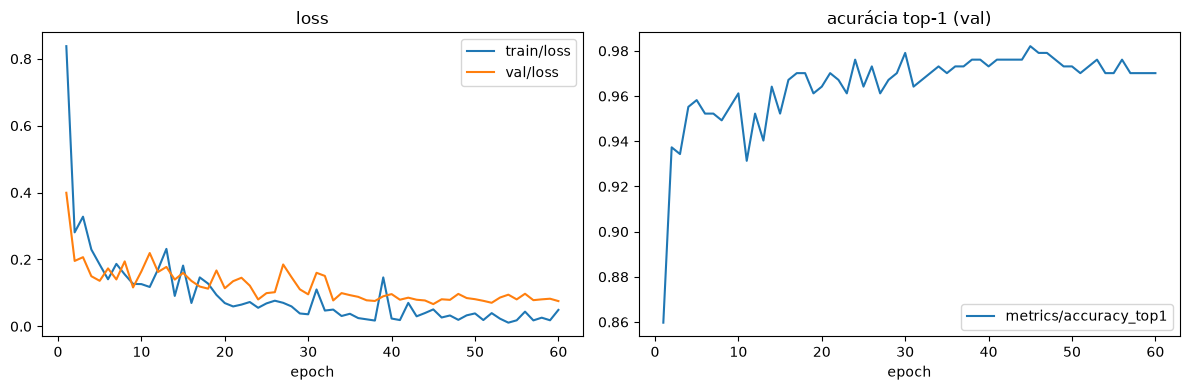

In [11]:
hist = pd.read_csv(SAVE_DIR / 'results.csv')
hist.columns = hist.columns.str.strip()
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
hist.plot(x='epoch', y=['train/loss', 'val/loss'], ax=ax[0], title='loss')
hist.plot(x='epoch', y=['metrics/accuracy_top1'], ax=ax[1], title='acurácia top-1 (val)')
plt.tight_layout(); plt.savefig(OUT / 'yolo_curvas.png', dpi=120); plt.show()

In [12]:
best = YOLO(SAVE_DIR / 'weights' / 'best.pt')
idx = {best.names[k]: CLASSES.index(best.names[k]) for k in best.names}  # índice YOLO -> índice deste notebook
paths_te = [str(p) for p in splits['test'][0]]

best.predict(paths_te[:8], imgsz=IMGSZ, verbose=False)  # aquecimento da GPU, fora da medição
pred_dl, t0 = [], time.perf_counter()
for i in tqdm(range(0, len(paths_te), 32), desc='teste YOLO'):
    for r in best.predict(paths_te[i:i + 32], imgsz=IMGSZ, verbose=False):
        pred_dl.append(idx[best.names[r.probs.top1]])
pred_dl = np.array(pred_dl)
ms_dl = (time.perf_counter() - t0) / len(pred_dl) * 1000

print(f'{YOLO_MODEL} | {ms_dl:.1f} ms/imagem (lotes de 32, GPU)\n')
print(classification_report(y['test'], pred_dl, target_names=LABELS, digits=3))

teste YOLO:   0%|          | 0/11 [00:00<?, ?it/s]

teste YOLO:   9%|▉         | 1/11 [00:01<00:10,  1.03s/it]

teste YOLO:  45%|████▌     | 5/11 [00:01<00:01,  5.60it/s]

teste YOLO:  82%|████████▏ | 9/11 [00:01<00:00, 10.39it/s]

teste YOLO: 100%|██████████| 11/11 [00:01<00:00,  8.38it/s]

yolo26s-cls.pt | 3.9 ms/imagem (lotes de 32, GPU)

               precision    recall  f1-score   support

     saudável      0.975     1.000     0.987        39
bicho-mineiro      0.929     0.940     0.934        83
     ferrugem      0.989     0.979     0.984        94
        phoma      0.957     0.957     0.957        69
   cercospora      0.918     0.900     0.909        50

     accuracy                          0.955       335
    macro avg      0.954     0.955     0.954       335
 weighted avg      0.955     0.955     0.955       335



## 4. Comparação ML x DL (conjunto de teste)

In [13]:
def resumo(yp, ms):
    yt = y['test']
    return {'precision (macro)': precision_score(yt, yp, average='macro'),
            'recall (macro)': recall_score(yt, yp, average='macro'),
            'F1 (macro)': f1_score(yt, yp, average='macro'),
            'F1 (weighted)': f1_score(yt, yp, average='weighted'),
            'acurácia': accuracy_score(yt, yp), 'ms/imagem': ms}

comp = pd.DataFrame({f'ML: {nome_ml}': resumo(pred_ml, ms_ml), f'DL: {Path(YOLO_MODEL).stem}': resumo(pred_dl, ms_dl)}).T
comp['meta F1'] = [0.60, 0.80]
comp['atingiu'] = comp['F1 (macro)'] >= comp['meta F1']
comp.round(3)

,precision (macro),recall (macro),F1 (macro),F1 (weighted),acurácia,ms/imagem,meta F1,atingiu
ML: SVM (RBF),0.827,0.844,0.832,0.838,0.836,18.291,0.6,True
DL: yolo26s-cls,0.954,0.955,0.954,0.955,0.955,3.921,0.8,True


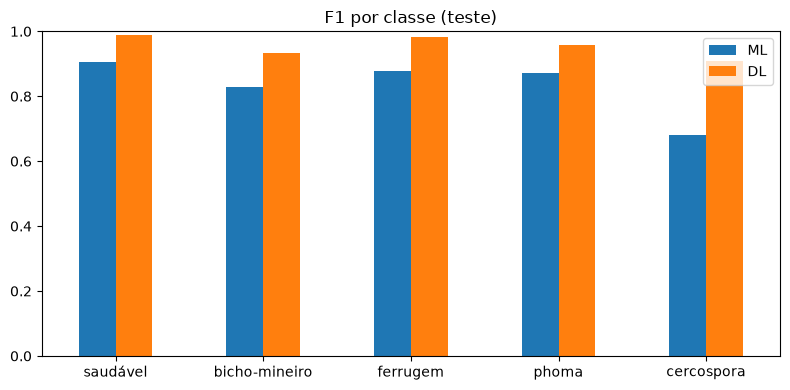

,ML,DL
saudável,0.905,0.987
bicho-mineiro,0.828,0.934
ferrugem,0.877,0.984
phoma,0.871,0.957
cercospora,0.679,0.909


In [14]:
f1_classe = pd.DataFrame({'ML': f1_score(y['test'], pred_ml, average=None), 'DL': f1_score(y['test'], pred_dl, average=None)}, index=LABELS)
f1_classe.plot.bar(figsize=(8, 4), title='F1 por classe (teste)', rot=0, ylim=(0, 1))
plt.tight_layout(); plt.savefig(OUT / 'f1_por_classe.png', dpi=120); plt.show()
f1_classe.round(3)

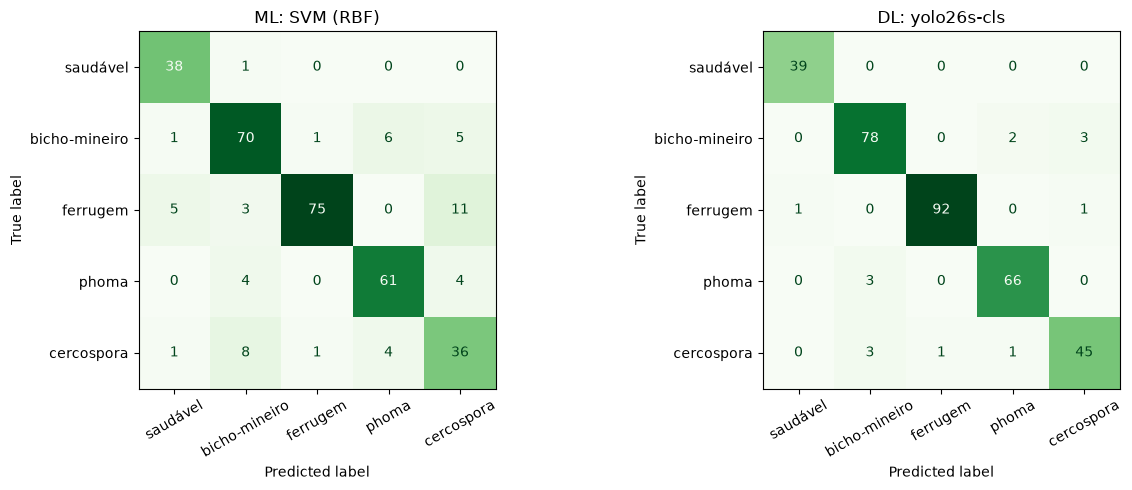

In [15]:
fig, axs = plt.subplots(1, 2, figsize=(13, 5))
for ax, (titulo, yp) in zip(axs, [(f'ML: {nome_ml}', pred_ml), (f'DL: {Path(YOLO_MODEL).stem}', pred_dl)]):
    ConfusionMatrixDisplay(confusion_matrix(y['test'], yp), display_labels=LABELS).plot(ax=ax, cmap='Greens', colorbar=False, xticks_rotation=30)
    ax.set_title(titulo)
plt.tight_layout(); plt.savefig(OUT / 'matrizes_confusao.png', dpi=120); plt.show()

### 4.1 Análise visual de acertos e falhas

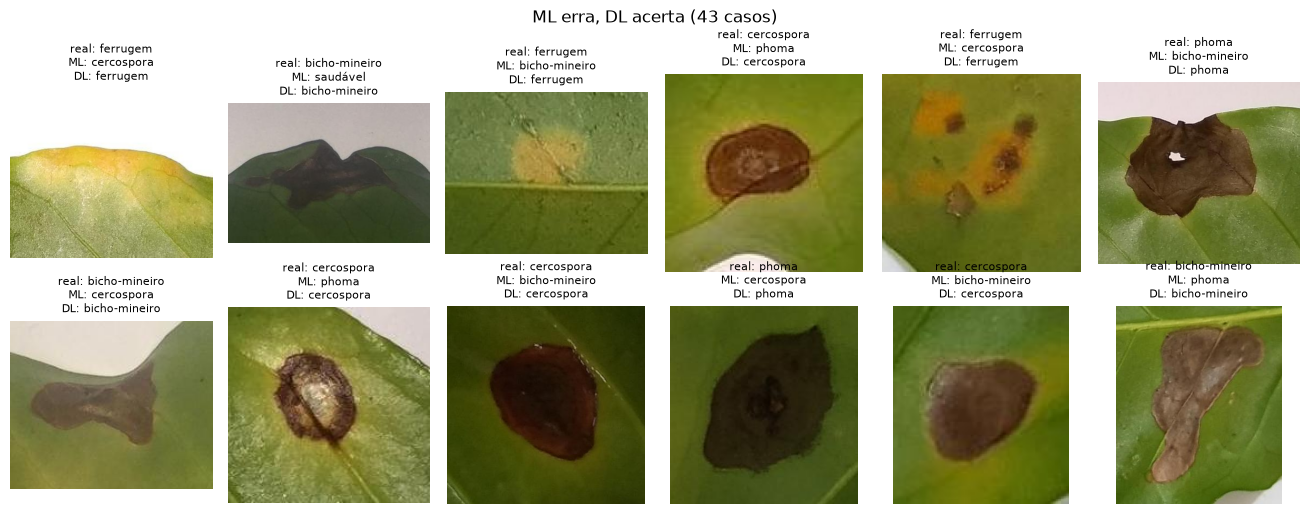

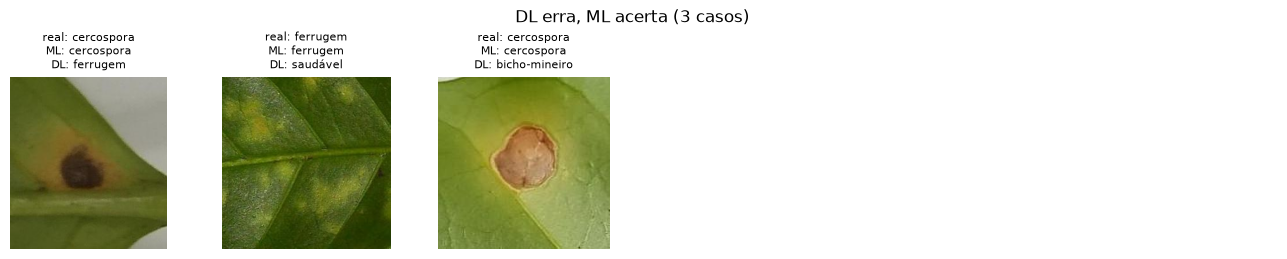

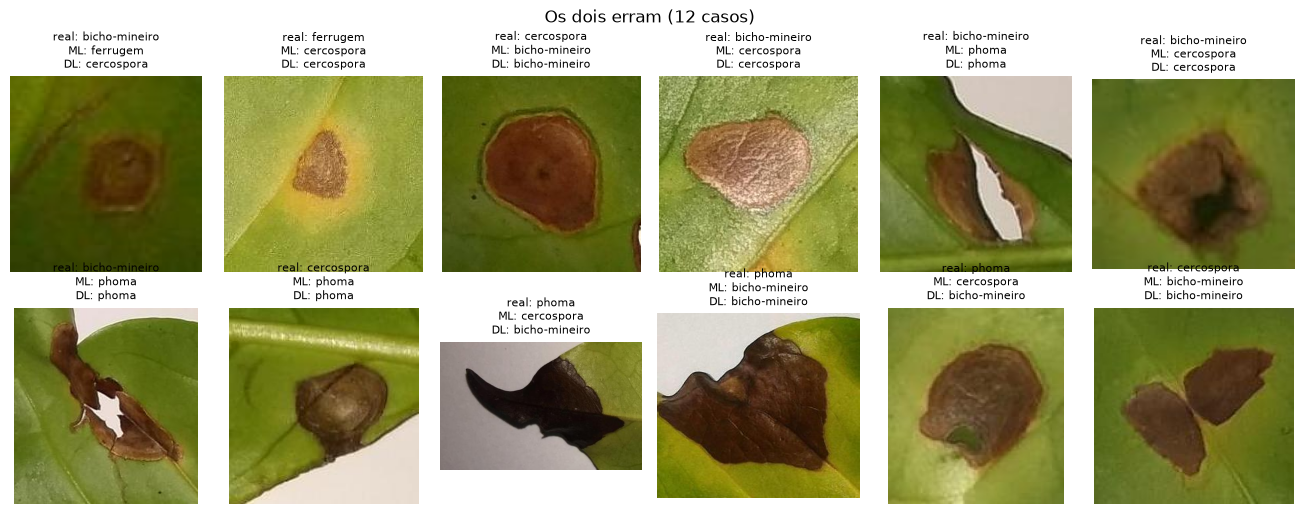

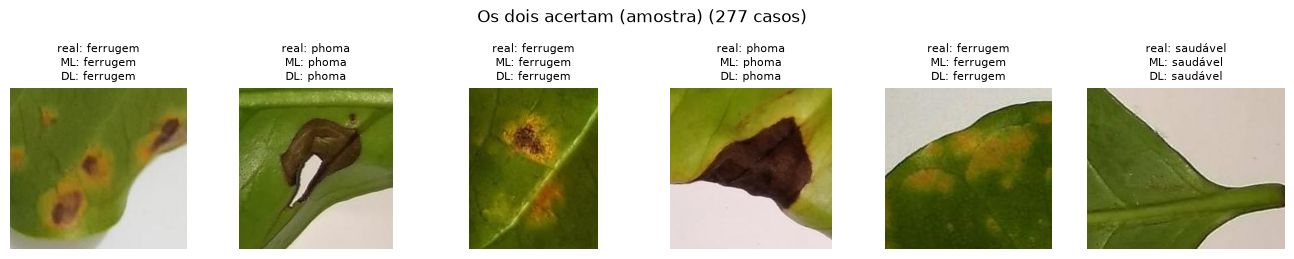

In [16]:
def grade(mascara, titulo, arquivo, n=12):
    ids = np.flatnonzero(mascara)
    ids = np.random.default_rng(SEED).choice(ids, min(n, len(ids)), replace=False) if len(ids) else []
    if not len(ids):
        print(titulo, ': nenhum caso'); return
    cols = 6; rows = int(np.ceil(len(ids) / cols))
    fig, axs = plt.subplots(rows, cols, figsize=(2.2 * cols, 2.6 * rows), squeeze=False)
    for ax in axs.ravel(): ax.axis('off')
    for ax, i in zip(axs.ravel(), ids):
        ax.imshow(cv2.cvtColor(cv2.imread(paths_te[i]), cv2.COLOR_BGR2RGB))
        ax.set_title(f'real: {LABELS[y["test"][i]]}\nML: {LABELS[pred_ml[i]]}\nDL: {LABELS[pred_dl[i]]}', fontsize=8)
    fig.suptitle(f'{titulo} ({len(np.flatnonzero(mascara))} casos)'); plt.tight_layout(); plt.savefig(OUT / arquivo, dpi=120); plt.show()

yt = y['test']
grade((pred_ml != yt) & (pred_dl == yt), 'ML erra, DL acerta', 'erros_so_ml.png')
grade((pred_dl != yt) & (pred_ml == yt), 'DL erra, ML acerta', 'erros_so_dl.png')
grade((pred_ml != yt) & (pred_dl != yt), 'Os dois erram', 'erros_ambos.png')
grade((pred_ml == yt) & (pred_dl == yt), 'Os dois acertam (amostra)', 'acertos_ambos.png', n=6)

In [17]:
resultado = {
    'ml': {'modelo': nome_ml, 'params': params_ml, 'atributos': GRUPOS, **resumo(pred_ml, ms_ml)},
    'dl': {'modelo': YOLO_MODEL, 'imgsz': IMGSZ, 'epocas_rodadas': int(hist['epoch'].max()), **resumo(pred_dl, ms_dl)},
    'ablacao_val': ablacao.to_dict(),
}
(OUT / 'metricas.json').write_text(json.dumps(resultado, indent=2, ensure_ascii=False, default=float))
print(json.dumps(resultado, indent=2, ensure_ascii=False, default=float))

{
  "ml": {
    "modelo": "SVM (RBF)",
    "params": {
      "C": 100,
      "gamma": 0.001
    },
    "atributos": [
      "cor",
      "lbp",
      "glcm"
    ],
    "precision (macro)": 0.8268871958554239,
    "recall (macro)": 0.8439325559549806,
    "F1 (macro)": 0.8322062217058781,
    "F1 (weighted)": 0.8375823482561505,
    "acurácia": 0.835820895522388,
    "ms/imagem": 18.290634985071428
  },
  "dl": {
    "modelo": "yolo26s-cls.pt",
    "imgsz": 224,
    "epocas_rodadas": 60,
    "precision (macro)": 0.9535415652937191,
    "recall (macro)": 0.9550008359060665,
    "F1 (macro)": 0.9542086752303052,
    "F1 (weighted)": 0.955181454656214,
    "acurácia": 0.9552238805970149,
    "ms/imagem": 3.9211294656565565
  },
  "ablacao_val": {
    "cor+lbp+glcm": 0.8450057330772456,
    "cor+lbp+glcm+hog": 0.8110646754733342,
    "cor": 0.7744852018183769,
    "lbp": 0.6862315830466389,
    "hog": 0.6245932547576357,
    "glcm": 0.5705206246884804
  }
}
